# EcoLar · 02 / Agrupamento de padrões semanais
**Equipe:** Yan Almeida RM568814 · Vinicius Pacheco Ruiz RM571109 · Diego Barbosa RM568829.
Turma 1TDSPV. Modelo não supervisionado: StandardScaler + KMeans.

**Pergunta:** quais semanas da casa de referência apresentam características de consumo semelhantes?
Não estamos segmentando famílias brasileiras nem detectando desperdício comprovado.

## Fonte, transformação e limites
Hebrail e Berard, **Individual Household Electric Power Consumption**, UCI, DOI
[10.24432/C58K54](https://doi.org/10.24432/C58K54), CC BY 4.0.
Uma residência francesa, medições de minuto em 2006–2010. A energia diária é
`soma(Global_active_power) / 60`, pois a potência está em kW e cada leitura representa um minuto.
Só entram dias com 1.440 minutos válidos. Não dividimos conta mensal por 30, não preenchemos
ausências com zero e não usamos os dados simulados do Oracle para treinar.

Os CSVs derivados utilizados no treinamento já estão incluídos em `dados/`.
`preparar_dados.py` reproduz a derivação a partir do download oficial; o arquivo
`dados/fonte.json` registra origem, regra e SHA-256 do ZIP original.
**Este experimento não comprova desempenho em outras casas ou no Brasil.**

In [1]:
from pathlib import Path
import sys, os, json
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '2')
raiz = Path.cwd()
if not (raiz / 'ecolar_ia').exists(): raiz = raiz.parent
assert (raiz / 'ecolar_ia').exists(), 'Abra a pasta EcoLar_IA no VS Code.'
sys.path.insert(0, str(raiz))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
from ecolar_ia import VERSAO
from ecolar_ia.dados import RAIZ, carregar_diario
from ecolar_ia.features import COLUNAS_REGRESSAO, COLUNAS_GRUPO, tabela_regressao, tabela_grupos
from ecolar_ia.treino import salvar_json, metricas_regressao, qualidade_grupos, registrar_ambiente
plt.rcParams.update({'figure.figsize':(10,4), 'axes.spines.top':False, 'axes.spines.right':False})
figuras = RAIZ / 'resultados/graficos'
figuras.mkdir(parents=True, exist_ok=True)
diario = carregar_diario()
display(diario.head())

,data,consumo_kwh
0,2006-12-17,56.507667
1,2006-12-18,36.730433
2,2006-12-19,27.769900
3,2006-12-20,37.095800
4,2006-12-22,39.022300


## 1. Dados e análise exploratória

,data_inicio,data_fim,media_kwh,desvio_kwh,minimo_kwh,maximo_kwh,media_dias_uteis_kwh,media_fim_semana_kwh
0,2007-01-01,2007-01-07,35.621590,13.321758,16.900900,54.323533,36.683567,32.966650
1,2007-01-15,2007-01-21,39.346824,11.777183,24.674000,56.787700,33.282240,54.508283
2,2007-01-29,2007-02-04,40.886600,14.891401,27.795600,67.162033,31.822367,63.547183
3,2007-02-05,2007-02-11,35.878443,12.501185,21.224667,59.520467,28.894633,53.337967
4,2007-02-12,2007-02-18,36.631848,12.239147,23.575767,63.829367,31.595673,49.222283


,media_kwh,desvio_kwh,minimo_kwh,maximo_kwh,media_dias_uteis_kwh,media_fim_semana_kwh
count,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000
mean,25.627338,5.282830,18.605276,34.564408,24.265319,29.032384
std,7.607647,2.700267,6.388023,10.968871,7.148759,10.384056
min,4.415957,0.128165,4.244033,4.578200,4.484480,4.244650
25%,20.539404,3.318487,14.195617,27.573175,19.391432,22.923288
50%,26.275874,5.154330,19.046883,34.180633,24.969467,29.463292
75%,30.942006,6.278846,23.691217,41.165892,29.281487,35.009188
max,45.324329,14.891401,37.630800,67.162033,43.927820,63.547183


Semanas completas, não sobrepostas: 138


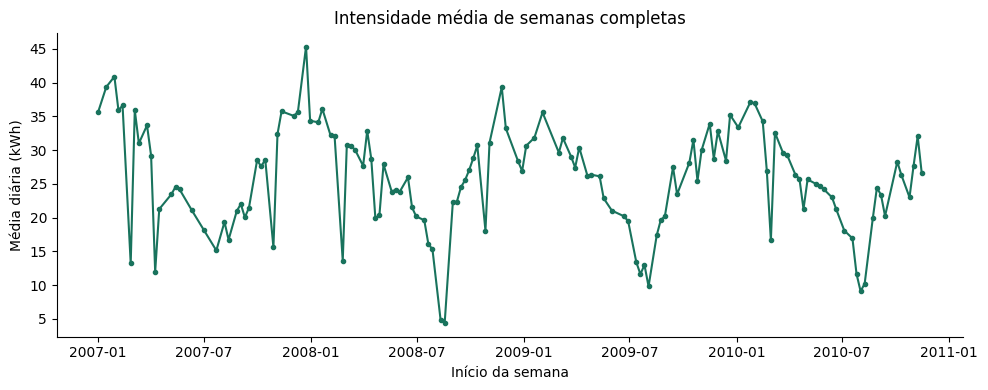

In [2]:
semanas=tabela_grupos(diario)
display(semanas.head())
display(semanas[COLUNAS_GRUPO].describe())
print('Semanas completas, não sobrepostas:',len(semanas))
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(semanas.data_inicio,semanas.media_kwh,'o-',markersize=3,color='#19735d')
ax.set(title='Intensidade média de semanas completas',xlabel='Início da semana',ylabel='Média diária (kWh)')
fig.tight_layout();fig.savefig(figuras/'04_semanas.png',dpi=150);plt.show()

## 2. Preparação e escolha do número de grupos
Usamos semanas segunda-domingo completas, sem sobreposição, para evitar amostras quase
idênticas dos mesmos dias. Atributos: média, desvio padrão populacional, mínimo, máximo,
média dos dias úteis e média do fim de semana, todos em kWh/dia.

Os atributos são correlacionados e priorizam **intensidade**; este modelo não distingue todos os
hábitos possíveis. StandardScaler é ajustado somente no primeiro 80% das semanas; o teste é
cronologicamente posterior. KMeans é sensível a escala e a valores extremos.
Comparamos k de 2 a 5 pela silhouette do treino. Essa escolha favorece a separação nessa amostra;
o teste posterior é descritivo e não participa da seleção. Não existe rótulo verdadeiro para calcular acurácia.

In [3]:
tabela = tabela_grupos(carregar_diario())
corte = int(len(tabela) * .8)
treino, teste = tabela.iloc[:corte], tabela.iloc[corte:]
candidatos, pipelines = [], {}
for k in range(2,6):
    pipe = Pipeline([("escala",StandardScaler()),
                     ("kmeans",KMeans(n_clusters=k, n_init=20, random_state=42))])
    pipe.fit(treino[COLUNAS_GRUPO])
    x = pipe.named_steps["escala"].transform(treino[COLUNAS_GRUPO])
    rotulos = pipe.named_steps["kmeans"].labels_
    candidatos.append({"k":k, **qualidade_grupos(x,rotulos)})
    pipelines[k] = pipe
escolhido = max(candidatos, key=lambda r:r["silhouette"])["k"]
pipe = pipelines[escolhido]
rotulos = pipe.predict(treino[COLUNAS_GRUPO])
resumo = treino[COLUNAS_GRUPO].copy()
resumo["grupo"] = rotulos
centros = resumo.groupby("grupo")[COLUNAS_GRUPO].mean()
ordem = centros.media_kwh.sort_values().index.tolist()
descricoes = {}
for pos,grupo in enumerate(ordem):
    nome = "Menor" if pos == 0 else "Maior" if pos == len(ordem)-1 else "Intermediária"
    descricoes[str(grupo)] = {"nome":f"{nome} intensidade relativa ({pos+1}/{escolhido})",
                              "media_diaria_treino_kwh":float(centros.loc[grupo,"media_kwh"]),
                              "semanas_treino":int((rotulos == grupo).sum()),
                              "interpretacao":"Comparação com semanas da casa de referência; não identifica desperdício nem causa."}
teste_grupos = pipe.predict(teste[COLUNAS_GRUPO])
xteste = pipe.named_steps["escala"].transform(teste[COLUNAS_GRUPO])
avaliacao = {"modelo":"StandardScaler + KMeans", "versao":VERSAO, "k_escolhido":escolhido,
            "semanas_treino":len(treino), "semanas_teste":len(teste),
            "periodo_treino":[str(treino.data_inicio.min().date()), str(treino.data_fim.max().date())],
            "periodo_teste":[str(teste.data_inicio.min().date()), str(teste.data_fim.max().date())],
            "candidatos_treino":candidatos, "qualidade_teste":qualidade_grupos(xteste,teste_grupos),
            "grupos":descricoes,
            "metodo":"Semanas segunda-domingo sem sobreposição. Corte cronológico 80/20. Escala e KMeans ajustados só no treino; k por silhouette do treino, teste descritivo separado.",
            "limite":"Agrupamento exploratório sem rótulo verdadeiro; silhouette não é acurácia. Uma casa não representa a população."}
tabela["particao"] = ["treino" if i < corte else "teste" for i in range(len(tabela))]
tabela["grupo"] = pipe.predict(tabela[COLUNAS_GRUPO])
tabela.to_csv(RAIZ / "dados/treinamento_agrupamento.csv", index=False)
salvar_json(RAIZ / "resultados/metricas_agrupamento.json", avaliacao)
centros.to_csv(RAIZ / "resultados/perfis_grupos_treino.csv")
bundle = {"modelo":pipe, "colunas":COLUNAS_GRUPO, "versao":VERSAO,
          "sklearn":sklearn.__version__, "tipo":"agrupamento", "avaliacao":avaliacao,
          "descricoes":descricoes,
          "minimos_treino":treino[COLUNAS_GRUPO].min().to_dict(),
          "maximos_treino":treino[COLUNAS_GRUPO].max().to_dict()}
joblib.dump(bundle, RAIZ / "modelos/agrupamento.joblib", compress=3)

['C:\\Users\\yanal\\Downloads\\EcoLar_IA_Projeto\\EcoLar_IA\\modelos\\agrupamento.joblib']

In [4]:
display(pd.DataFrame(candidatos).round(4))
display(pd.DataFrame(avaliacao['grupos']).T)
display(pd.Series(avaliacao['qualidade_teste']))
print('Treino:',avaliacao['periodo_treino'],'| Teste:',avaliacao['periodo_teste'])

,k,silhouette,davies_bouldin
0,2,0.4302,0.8355
1,3,0.3680,0.9417
2,4,0.3635,0.8794
3,5,0.3307,0.9282


,nome,media_diaria_treino_kwh,semanas_treino,interpretacao
0,Menor intensidade relativa (1/2),19.347054,50,Comparação com semanas da casa de referência; ...
1,Maior intensidade relativa (2/2),32.099474,60,Comparação com semanas da casa de referência; ...


silhouette        0.243790
davies_bouldin    1.021245
dtype: float64

Treino: ['2007-01-01', '2010-02-28'] | Teste: ['2010-03-01', '2010-11-21']


## 3. Visualização e interpretação

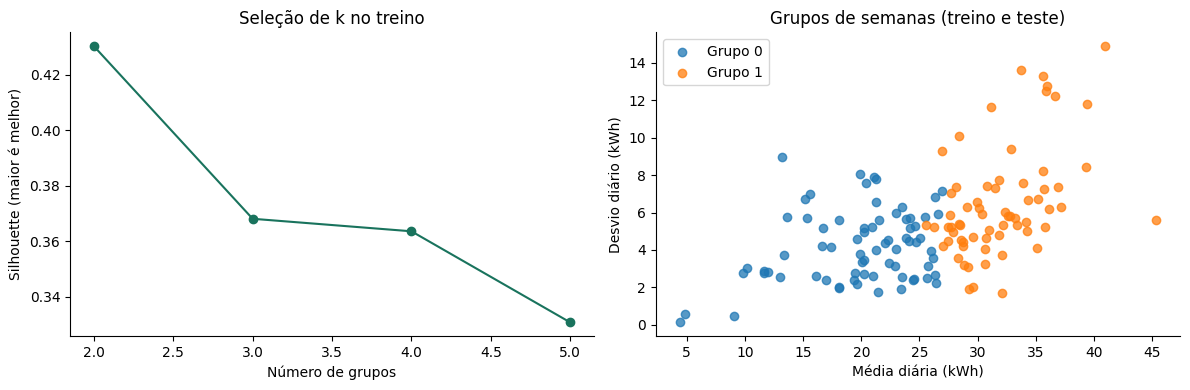

In [5]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
pd.DataFrame(candidatos).plot(x='k',y='silhouette',marker='o',ax=ax[0],legend=False,color='#19735d')
ax[0].set(title='Seleção de k no treino',xlabel='Número de grupos',ylabel='Silhouette (maior é melhor)')
for g in sorted(tabela.grupo.unique()):
    sub=tabela[tabela.grupo.eq(g)]
    ax[1].scatter(sub.media_kwh,sub.desvio_kwh,label=f'Grupo {g}',alpha=.75)
ax[1].set(title='Grupos de semanas (treino e teste)',xlabel='Média diária (kWh)',ylabel='Desvio diário (kWh)')
ax[1].legend();fig.tight_layout();fig.savefig(figuras/'05_agrupamento.png',dpi=150);plt.show()

## 4. Avaliação responsável
Silhouette varia de -1 a 1, indicando separação relativa entre grupos no espaço padronizado.
Davies–Bouldin menor indica grupos relativamente mais compactos e separados.
As métricas avaliam geometria dos atributos; não provam utilidade para o morador nem causalidade.
O teste com k escolhido pode apresentar separação menor que o treino, e isso deve ser reportado.

Os nomes dos grupos são atribuídos depois do treinamento pela média de consumo no treino,
ordenada de menor a maior. Os números 0/1/etc. são identificadores arbitrários, não classes de
desperdício. Uma semana intensa pode refletir mais moradores ou necessidades legítimas.
Não recomendamos reduzir uso essencial apenas com base no grupo.

In [6]:
display(Markdown(f"**k escolhido: {escolhido}**. Silhouette de teste: "
 f"**{avaliacao['qualidade_teste']['silhouette']:.3f}**. "
 'O agrupamento é exploratório; a separação no teste é inferior à observada no treino.'))
registrar_ambiente()
print('Pipeline completo (padronização + KMeans) exportado:',RAIZ/'modelos/agrupamento.joblib')

**k escolhido: 2**. Silhouette de teste: **0.244**. O agrupamento é exploratório; a separação no teste é inferior à observada no treino.

Pipeline completo (padronização + KMeans) exportado: C:\Users\yanal\Downloads\EcoLar_IA_Projeto\EcoLar_IA\modelos\agrupamento.joblib


## 5. Integração, limitações e fontes
`/agrupar` usa os mesmos atributos e o pipeline exportado, sem novo fit na requisição.
Aceita sete dias consecutivos; se não começarem numa segunda-feira, retorna aviso sobre
alinhamento diferente do treino. Entradas fora da faixa observada também geram aviso.

Validação futura: dados de mais casas, comparação com outras representações de forma semanal,
estabilidade por estação e testes com usuários para verificar se a interpretação é compreensível.

[KMeans e silhouette](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html),
[fonte UCI](https://doi.org/10.24432/C58K54). Consulta 11/11/2026.